# ДЗ 4. Сравнение методов градиентного спуска

In [1]:
from pathlib import Path
import json

import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import f, t
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
ALPHA = 0.05
CORR_LIMIT = 0.9
N_STEPS = 5000
N_FOLDS = 5
STEP_GRID = np.logspace(-5, 0, 11)
INITIAL_STEP = 0.1
TARGET = "Стоимость_квартиры_тыс_руб"
METHODS = ["VGD", "SGD", "SAG", "Momentum", "Adam"]

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (BASE / "regression_data.csv").exists():
    BASE = BASE / "fourth"
OUT = BASE / "results"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def show_table(table):
    if "get_ipython" in globals():
        display(table)
    else:
        print(table.to_string())


def save_table(table, name):
    table.to_csv(OUT / f"{name}.csv", encoding="utf-8-sig", index=True)


def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")
    if "get_ipython" in globals():
        plt.show()
    else:
        plt.close(fig)


def design_matrix(x):
    return np.column_stack([np.ones(len(x)), x])


def metrics(y, prediction):
    mse = float(np.mean((np.asarray(y) - prediction) ** 2))
    r2 = 1 - mse / np.var(y)
    return {"MSE": mse, "RMSE": float(np.sqrt(mse)), "R2": float(r2)}

## 2.1. Данные и обучение на train
Train / val / test: 80 / 10 / 10. ID исключается, день недели кодируется.

In [2]:
df = pd.read_csv(BASE / "regression_data.csv")
if df.isna().any().any():
    raise ValueError("В данных есть пропуски")
X = df.drop(columns=[TARGET, "ID_объекта"])
y = df[TARGET]
train_idx, rest_idx = train_test_split(df.index, test_size=0.2, random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, random_state=SEED)
X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_val, y_val = X.loc[val_idx], y.loc[val_idx]
X_test, y_test = X.loc[test_idx], y.loc[test_idx]
print(f"Данные: {df.shape}; train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}")
show_table(df.head())
split = pd.Series(index=df.index, dtype="object", name="Выборка")
for name, indices in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    split.loc[indices] = name
save_table(pd.concat([df["ID_объекта"], split], axis=1), "split")


def fit_encoding(raw):
    categories = {name: sorted(raw[name].unique())
                  for name in raw.select_dtypes(include=["object", "category"])}
    return categories


def encode(raw, categories):
    result = raw.drop(columns=list(categories)).astype(float).copy()
    groups = {name: [name] for name in result.columns}
    for name, levels in categories.items():
        groups[name] = []
        for level in levels[1:]:
            column = f"{name}={level}"
            result[column] = (raw[name] == level).astype(float)
            groups[name].append(column)
    return result, groups


def fit_for_statistics(x, target):
    xs = StandardScaler().fit(x)
    ys = StandardScaler().fit(np.asarray(target).reshape(-1, 1))
    a = design_matrix(xs.transform(x))
    z = ys.transform(np.asarray(target).reshape(-1, 1)).ravel()
    n, p = a.shape
    if n <= p or np.linalg.matrix_rank(a) < p:
        raise ValueError("Недостаточно наблюдений или матрица X вырождена")
    hessian = 2 * np.dot(a.T, a) / n
    rhs = 2 * np.dot(a.T, z) / n
    eta = 0.9 / np.linalg.eigvalsh(hessian).max()
    w = np.zeros(p)
    for iteration in range(1, 200001):
        gradient = np.dot(hessian, w) - rhs
        if np.linalg.norm(gradient) < 1e-10:
            break
        w -= eta * gradient
    else:
        raise RuntimeError("VGD не сошёлся для проверки значимости")
    reference = np.linalg.lstsq(a, z, rcond=None)[0]
    if not np.allclose(w, reference, atol=1e-6, rtol=1e-6):
        raise RuntimeError("VGD не достиг решения МНК")
    prediction = ys.mean_[0] + ys.scale_[0] * np.dot(a, w)
    rss = float(np.sum((np.asarray(target) - prediction) ** 2))
    dof = n - p
    transform = np.eye(p)
    transform[0, 1:] = -xs.mean_ / xs.scale_
    transform[1:, 1:] = np.diag(1 / xs.scale_)
    coefficients = ys.scale_[0] * np.dot(transform, w)
    coefficients[0] += ys.mean_[0]
    covariance = rss / dof * np.dot(
        np.dot(transform, np.linalg.inv(np.dot(a.T, a))), transform.T
    )
    standard_error = np.sqrt(np.diag(covariance))
    t_values = coefficients / standard_error
    p_values = 2 * t.sf(np.abs(t_values), dof)
    coefficient_table = pd.DataFrame({
        "Коэффициент": coefficients, "Стандартная ошибка": standard_error,
        "t": t_values, "p-value": p_values, "Значим": p_values < ALPHA,
    }, index=["const"] + list(x.columns))
    tss = float(np.sum((np.asarray(target) - np.mean(target)) ** 2))
    f_value = max(0, (tss - rss) / (p - 1)) / (rss / dof)
    model_table = pd.DataFrame([{
        "R2_train": 1 - rss / tss, "F": f_value,
        "F_крит": f.ppf(1 - ALPHA, p - 1, dof),
        "p-value": f.sf(f_value, p - 1, dof),
        "Значима": f.sf(f_value, p - 1, dof) < ALPHA,
        "Итерации VGD": iteration,
    }])
    return {"coefficients": coefficient_table, "model": model_table,
            "rss": rss, "dof": dof, "prediction": prediction}


categories = fit_encoding(X_train)
encoded_train, groups = encode(X_train, categories)
initial_stats = fit_for_statistics(encoded_train, y_train)
print("VGD обучен на train")

Данные: (800, 13); train: 640, val: 80, test: 80
VGD обучен на train


,ID_объекта,Общая_площадь_м2,Жилая_площадь_м2,Количество_комнат,Этаж,Год_постройки,Расстояние_до_метро_мин,Расстояние_до_метро_м,Номер_подъезда,Код_домофона,День_недели_публикации,Случайный_показатель_шум,Стоимость_квартиры_тыс_руб
0,10001,69.9,46.2,2,2,2020,10.2,813,6,684,Чт,42.18,14785.1
1,10002,134.5,78.9,5,11,1984,23.1,1866,4,968,Пн,44.52,23038.5
2,10003,110.0,66.2,5,10,2010,24.0,2025,5,567,Пт,44.82,20917.6
3,10004,95.0,59.7,4,15,2008,7.4,516,7,965,Ср,52.59,19347.4
4,10005,45.5,27.0,3,17,1971,20.6,1706,9,637,Пн,31.69,8173.2


## 2.2. Значимость модели
F-тест: H₀ — все коэффициенты при признаках равны нулю. α = 0.05.

In [3]:
show_table(initial_stats["model"].round(6))
save_table(initial_stats["model"], "model_significance_initial")

,R2_train,F,F_крит,p-value,Значима,Итерации VGD
0,0.993921,6366.522098,1.659759,0.0,True,22857


## 2.3. Значимость признаков
t-тесты для числовых признаков, общий F-тест для дня недели.
Удаляем незначимые признаки из X. Столбец y сохраняется.

In [4]:
def select_by_significance(x, target, feature_groups):
    selected = list(x.columns)
    removed, tests = [], []
    while selected:
        current = x[selected]
        stats = fit_for_statistics(current, target)
        group_tests = []
        for group, columns in feature_groups.items():
            columns = [name for name in columns if name in selected]
            if not columns:
                continue
            if len(columns) == 1:
                p_value = float(stats["coefficients"].loc[columns[0], "p-value"])
            else:
                reduced = design_matrix(current.drop(columns=columns))
                fitted = np.dot(reduced, np.linalg.lstsq(reduced, target, rcond=None)[0])
                rss_reduced = np.sum((np.asarray(target) - fitted) ** 2)
                statistic = max(0, (rss_reduced - stats["rss"]) / len(columns))
                statistic /= stats["rss"] / stats["dof"]
                p_value = float(f.sf(statistic, len(columns), stats["dof"]))
            group_tests.append({"Шаг": len(removed) + 1, "Признак": group,
                                "p-value": p_value, "Удалён": False})
        worst = max(group_tests, key=lambda row: row["p-value"])
        if worst["p-value"] <= ALPHA:
            tests.extend(group_tests)
            return selected, pd.DataFrame(removed), pd.DataFrame(tests), stats
        worst["Удалён"] = True
        tests.extend(group_tests)
        removed.append({"Признак": worst["Признак"], "Причина": "p-value > 0.05",
                        "Значение": worst["p-value"]})
        selected = [name for name in selected if name not in feature_groups[worst["Признак"]]]
    raise ValueError("Все признаки оказались незначимыми")


significant, removed_p, significance_steps, significant_stats = select_by_significance(
    encoded_train, y_train, groups
)
show_table(initial_stats["coefficients"].round(6))
show_table(significance_steps.round(6))
save_table(initial_stats["coefficients"], "coefficients_initial")
save_table(significance_steps, "significance_steps")
save_table(removed_p, "removed_by_significance")

,Коэффициент,Стандартная ошибка,t,p-value,Значим
const,-90654.696589,2408.362963,-37.641625,0.000000,True
Общая_площадь_м2,179.509225,3.134873,57.262043,0.000000,True
Жилая_площадь_м2,-3.813151,4.474047,-0.852282,0.394385,False
Количество_комнат,-26.089064,35.537958,-0.734118,0.463153,False
Этаж,24.355237,2.592111,9.395907,0.000000,True
Год_постройки,46.654538,1.202196,38.807748,0.000000,True
Расстояние_до_метро_мин,-61.944587,31.060936,-1.994292,0.046555,True
Расстояние_до_метро_м,-0.410599,0.387322,-1.060098,0.289511,False
Номер_подъезда,12.805492,7.049612,1.816482,0.069777,False
Код_домофона,-0.043920,0.073694,-0.595980,0.551405,False


,Шаг,Признак,p-value,Удалён
0,1,Общая_площадь_м2,0.000000,False
1,1,Жилая_площадь_м2,0.394385,False
2,1,Количество_комнат,0.463153,False
3,1,Этаж,0.000000,False
4,1,Год_постройки,0.000000,False
5,1,Расстояние_до_метро_мин,0.046555,False
6,1,Расстояние_до_метро_м,0.289511,False
7,1,Номер_подъезда,0.069777,False
8,1,Код_домофона,0.551405,False
9,1,Случайный_показатель_шум,0.611146,True


## 2.4. Парные корреляции
При |r| ≥ 0.9 оставляем признак с большей |корреляцией с y| на train.
После удаления повторяем проверку значимости.

Оставлены: Общая_площадь_м2, Этаж, Год_постройки, Расстояние_до_метро_мин


,Общая_площадь_м2,Этаж,Год_постройки,Расстояние_до_метро_мин,Стоимость_квартиры_тыс_руб
Общая_площадь_м2,1.000,-0.044,0.001,-0.005,0.977
Этаж,-0.044,1.000,-0.086,0.002,-0.024
Год_постройки,0.001,-0.086,1.000,-0.024,0.124
Расстояние_до_метро_мин,-0.005,0.002,-0.024,1.000,-0.159
Стоимость_квартиры_тыс_руб,0.977,-0.024,0.124,-0.159,1.000


,Признак,Причина,Значение
0,Случайный_показатель_шум,p-value > 0.05,0.611146
1,Код_домофона,p-value > 0.05,0.509965
2,Количество_комнат,p-value > 0.05,0.475967
3,Жилая_площадь_м2,p-value > 0.05,0.352855
4,Расстояние_до_метро_м,p-value > 0.05,0.262298
5,День_недели_публикации,p-value > 0.05,0.197625
6,Номер_подъезда,p-value > 0.05,0.077513


,Коэффициент,Стандартная ошибка,t,p-value,Значим
const,-90257.962441,2389.327026,-37.775475,0.0,True
Общая_площадь_м2,176.212391,0.564978,311.892572,0.0,True
Этаж,24.290606,2.582144,9.407144,0.0,True
Год_постройки,46.480338,1.193626,38.940452,0.0,True
Расстояние_до_метро_мин,-95.077187,1.961732,-48.465950,0.0,True


,R2_train,F,F_крит,p-value,Значима,Итерации VGD
0,0.993774,25340.510363,2.385963,0.0,True,18


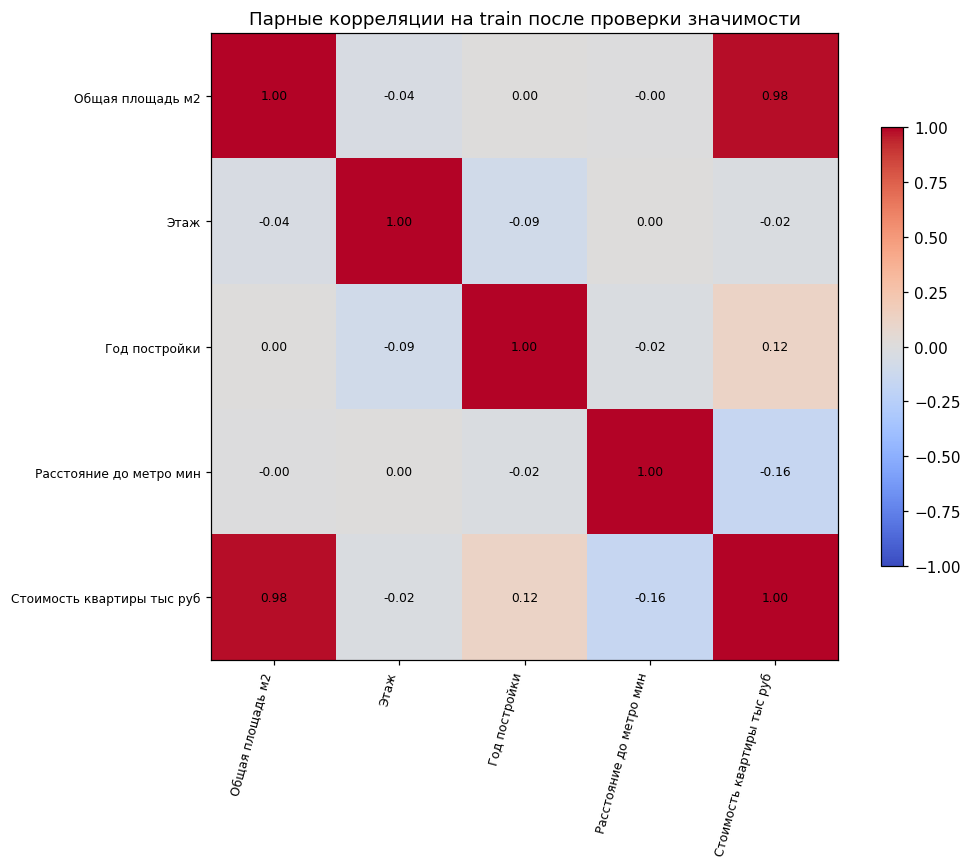

In [5]:
def select_by_correlation(x, target):
    selected = list(x.columns)
    removed = []
    while len(selected) > 1:
        corr = x[selected].corr().abs()
        upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)
        pairs = corr.where(upper).stack()
        if pairs.empty or pairs.max() < CORR_LIMIT:
            break
        left, right = pairs.idxmax()
        with_y = x[[left, right]].corrwith(target).abs()
        drop = left if with_y[left] < with_y[right] else right
        keep = right if drop == left else left
        removed.append({"Признак": drop, "Причина": f"Корреляция с {keep}",
                        "Значение": corr.loc[left, right]})
        selected.remove(drop)
    return selected, pd.DataFrame(removed)


def fit_selection(raw, target):
    levels = fit_encoding(raw)
    encoded, feature_groups = encode(raw, levels)
    significant_names, _, _, _ = select_by_significance(encoded, target, feature_groups)
    uncorrelated, _ = select_by_correlation(encoded[significant_names], target)
    final, _, _, _ = select_by_significance(encoded[uncorrelated], target, feature_groups)
    return levels, final


corr_initial = encoded_train.assign(**{TARGET: y_train}).corr()
corr_significant = encoded_train[significant].assign(**{TARGET: y_train}).corr()
uncorrelated, removed_corr = select_by_correlation(encoded_train[significant], y_train)
selected, removed_final, final_significance, final_stats = select_by_significance(
    encoded_train[uncorrelated], y_train, groups
)
corr_final = encoded_train[selected].assign(**{TARGET: y_train}).corr()
show_table(corr_significant.round(3))
removed = pd.concat([removed_p, removed_corr, removed_final], ignore_index=True)
show_table(removed.round(6))
print("Оставлены:", ", ".join(selected))
show_table(final_stats["coefficients"].round(6))
show_table(final_stats["model"].round(6))
for name, table in [("correlations_initial", corr_initial),
                    ("correlations_significant", corr_significant),
                    ("correlations_final", corr_final), ("removed_features", removed),
                    ("coefficients_final", final_stats["coefficients"]),
                    ("model_significance_final", final_stats["model"])]:
    save_table(table, name)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr_significant, cmap="coolwarm", vmin=-1, vmax=1)
labels = [name.replace("_", " ") for name in corr_significant.columns]
ax.set_xticks(range(len(labels)), labels, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr_significant.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Парные корреляции на train после проверки значимости")
fig.colorbar(image, ax=ax, shrink=0.7)
save_plot(fig, "correlations")

## 3.1. VGD, SGD, SAG, Momentum, Adam
L = MSE. По 5000 обновлений весов; ранней остановки нет, кроме расходимости.
SGD/SAG: одна строка за обновление; VGD/Momentum/Adam: весь train.
Постоянный шаг: η ∈ logspace(10⁻⁵, 1, 11).
TimeDecayLR: η(k) = 0.1 / (1 + λk), λ из той же сетки; k начинается с 0.

In [6]:
def fit_optimizer(a, z, method, step_type, value, seed=SEED, history=False):
    n, p = a.shape
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, n, size=N_STEPS)
    w = np.zeros(p)
    velocity, first, second = np.zeros(p), np.zeros(p), np.zeros(p)
    memory, mean_gradient = np.zeros((n, p)), np.zeros(p)
    hessian, rhs = 2 * np.dot(a.T, a) / n, 2 * np.dot(a.T, z) / n
    trajectory = []
    valid = True
    with np.errstate(over="ignore", invalid="ignore"):
        for k in range(N_STEPS):
            eta = value if step_type == "constant" else INITIAL_STEP / (1 + value * k)
            if method in ["SGD", "SAG"]:
                i = indices[k]
                gradient = 2 * (np.dot(a[i], w) - z[i]) * a[i]
                if method == "SAG":
                    mean_gradient += (gradient - memory[i]) / n
                    memory[i] = gradient
                    gradient = mean_gradient
            else:
                gradient = np.dot(hessian, w) - rhs
            if method == "Momentum":
                velocity = 0.9 * velocity + gradient
                w -= eta * velocity
            elif method == "Adam":
                first = 0.9 * first + 0.1 * gradient
                second = 0.999 * second + 0.001 * gradient ** 2
                corrected_first = first / (1 - 0.9 ** (k + 1))
                corrected_second = second / (1 - 0.999 ** (k + 1))
                w -= eta * corrected_first / (np.sqrt(corrected_second) + 1e-8)
            else:
                w -= eta * gradient
            if k % 50 == 0 or k == N_STEPS - 1:
                if not np.isfinite(w).all() or np.max(np.abs(w)) > 1e8:
                    valid = False
                    break
                if history:
                    loss = np.mean((np.dot(a, w) - z) ** 2)
                    trajectory.append((k + 1, float(loss)))
    return {"weights": w, "valid": valid, "iterations": k + 1,
            "history": np.asarray(trajectory)}


def prepare_fit(train_x, train_y, check_x, check_y):
    x_scaler = StandardScaler().fit(train_x)
    y_scaler = StandardScaler().fit(np.asarray(train_y).reshape(-1, 1))
    return {
        "a": design_matrix(x_scaler.transform(train_x)),
        "z": y_scaler.transform(np.asarray(train_y).reshape(-1, 1)).ravel(),
        "check": design_matrix(x_scaler.transform(check_x)),
        "check_y": np.asarray(check_y), "train_y": np.asarray(train_y),
        "x_scaler": x_scaler, "y_scaler": y_scaler,
    }


def predict(fit, a, weights):
    scaler = fit["y_scaler"]
    return scaler.mean_[0] + scaler.scale_[0] * np.dot(a, weights)


encoded_val, _ = encode(X_val, categories)
train_fit = prepare_fit(encoded_train[selected], y_train, encoded_val[selected], y_val)

## 3.2. R² и ошибка кросс-валидации
Обучение на train, подбор по val. 5-fold CV на train: отбор и масштабирование внутри фолда.
Ошибка CV — среднее RMSE по фолдам, в тыс. руб.

In [7]:
cv_fits, cv_features = [], []
for fold, (fit_idx, check_idx) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_train), 1):
    raw_fit, raw_check = X_train.iloc[fit_idx], X_train.iloc[check_idx]
    fold_y = y_train.iloc[fit_idx]
    fold_categories, fold_columns = fit_selection(raw_fit, fold_y)
    fold_x, _ = encode(raw_fit, fold_categories)
    fold_check, _ = encode(raw_check, fold_categories)
    cv_fits.append(prepare_fit(fold_x[fold_columns], fold_y,
                              fold_check[fold_columns], y_train.iloc[check_idx]))
    cv_features.append({"Фолд": fold, "Признаки": ", ".join(fold_columns)})
save_table(pd.DataFrame(cv_features), "cv_features")

rows, fold_rows = [], []
for method in METHODS:
    for step_type in ["constant", "time_decay"]:
        for value in STEP_GRID:
            fitted = fit_optimizer(train_fit["a"], train_fit["z"], method, step_type, value)
            train_metrics = {"RMSE": np.inf, "R2": -np.inf}
            val_metrics = {"RMSE": np.inf, "R2": -np.inf}
            if fitted["valid"]:
                train_metrics = metrics(y_train, predict(train_fit, train_fit["a"], fitted["weights"]))
                val_metrics = metrics(y_val, predict(train_fit, train_fit["check"], fitted["weights"]))
            cv_rmse, cv_r2 = [], []
            for fold, fold_fit in enumerate(cv_fits, 1):
                fold_model = fit_optimizer(fold_fit["a"], fold_fit["z"], method,
                                           step_type, value, seed=SEED + fold)
                fold_metrics = {"RMSE": np.inf, "R2": -np.inf}
                if fold_model["valid"]:
                    fold_prediction = predict(fold_fit, fold_fit["check"], fold_model["weights"])
                    fold_metrics = metrics(fold_fit["check_y"], fold_prediction)
                cv_rmse.append(fold_metrics["RMSE"])
                cv_r2.append(fold_metrics["R2"])
                fold_rows.append({"Метод": method, "Тип шага": step_type, "Параметр": value,
                                  "Фолд": fold, "RMSE": fold_metrics["RMSE"], "R2": fold_metrics["R2"]})
            cv_ok = bool(np.isfinite(cv_rmse).all())
            formula = (f"η = {value:.8g}" if step_type == "constant"
                       else f"η(k) = 0.1 / (1 + {value:.8g}k)")
            rows.append({
                "Метод": method, "Тип шага": step_type, "Параметр": value, "Шаг": formula,
                "RMSE_train": train_metrics["RMSE"], "R2_train": train_metrics["R2"],
                "RMSE_val": val_metrics["RMSE"], "R2_val": val_metrics["R2"],
                "CV_RMSE": float(np.mean(cv_rmse)) if cv_ok else np.inf,
                "CV_RMSE_std": float(np.std(cv_rmse, ddof=1)) if cv_ok else np.nan,
                "CV_R2": float(np.mean(cv_r2)) if cv_ok else -np.inf,
                "Итерации": fitted["iterations"],
                "Статус": "ok" if fitted["valid"] and cv_ok else "расходимость",
            })
    print(f"{method}: готово")

results = pd.DataFrame(rows)
save_table(results, "all_experiments")
save_table(pd.DataFrame(fold_rows), "cv_folds")
print(f"Проверено конфигураций: {len(results)}")

VGD: готово
SGD: готово
SAG: готово
Momentum: готово
Adam: готово
Проверено конфигураций: 110


## 3.3. Сравнительные таблицы

,Метод,Тип шага,Шаг,R2_train,R2_val,RMSE_train,RMSE_val,CV_RMSE,CV_RMSE_std
0,SAG,constant,η = 0.001,0.993728,0.995468,470.379137,401.488582,475.413105,29.498964
1,VGD,time_decay,η(k) = 0.1 / (1 + 0.31622777k),0.993705,0.995462,471.224415,401.737595,476.598158,32.601906
2,SGD,time_decay,η(k) = 0.1 / (1 + 0.31622777k),0.993596,0.995359,475.275734,406.249883,481.236581,35.564741
3,VGD,constant,η = 0.001,0.993774,0.995343,468.629011,406.977061,473.497764,30.994290
4,Momentum,constant,η = 0.0001,0.993774,0.995343,468.628978,406.985968,473.497154,30.993757
5,Adam,constant,η = 1,0.993774,0.995342,468.629030,407.029954,590.268737,248.294989
6,Adam,time_decay,η(k) = 0.1 / (1 + 1e-05k),0.993774,0.995341,468.628883,407.041199,475.224526,33.150417
7,Momentum,time_decay,η(k) = 0.1 / (1 + 0.1k),0.993774,0.995341,468.628883,407.041756,473.491896,30.992960
8,SAG,time_decay,η(k) = 0.1 / (1 + 0.031622777k),0.993741,0.995335,469.880126,407.338471,474.316288,31.349163
9,SGD,constant,η = 0.001,0.993751,0.995189,469.522038,413.661874,475.332673,31.525174


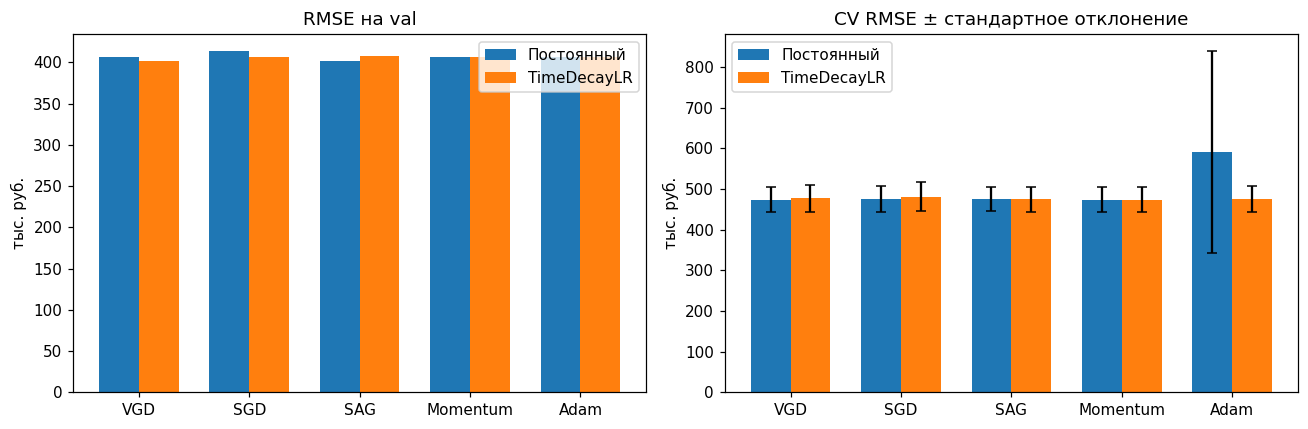

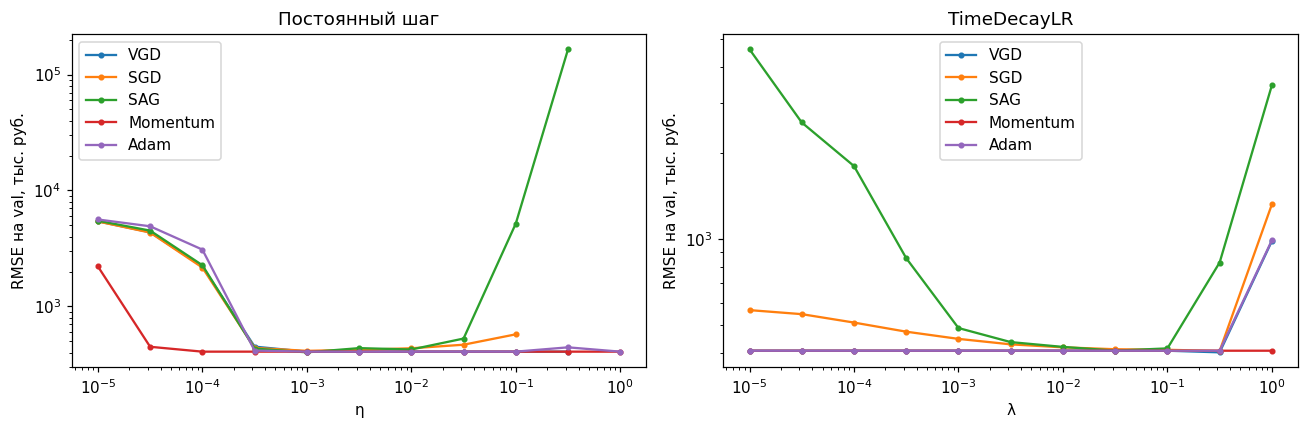

In [8]:
valid_results = results[results["Статус"] == "ok"].copy()
if valid_results.empty:
    raise RuntimeError("Нет устойчивых конфигураций")
comparison = (valid_results.sort_values(["RMSE_val", "CV_RMSE"], kind="stable")
              .drop_duplicates(["Метод", "Тип шага"]).reset_index(drop=True))
columns = ["Метод", "Тип шага", "Шаг", "R2_train", "R2_val",
           "RMSE_train", "RMSE_val", "CV_RMSE", "CV_RMSE_std"]
show_table(comparison[columns].round(6))
save_table(comparison, "comparison")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(len(METHODS))
for step_type, offset, label in [("constant", -0.18, "Постоянный"), ("time_decay", 0.18, "TimeDecayLR")]:
    part = comparison[comparison["Тип шага"] == step_type].set_index("Метод").reindex(METHODS)
    axes[0].bar(positions + offset, part["RMSE_val"], width=0.36, label=label)
    axes[1].bar(positions + offset, part["CV_RMSE"], width=0.36,
                yerr=part["CV_RMSE_std"], capsize=3, label=label)
for ax, title in zip(axes, ["RMSE на val", "CV RMSE ± стандартное отклонение"]):
    ax.set_xticks(positions, METHODS)
    ax.set_ylabel("тыс. руб.")
    ax.set_title(title)
    ax.legend()
save_plot(fig, "methods_comparison")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, step_type in zip(axes, ["constant", "time_decay"]):
    for method in METHODS:
        part = valid_results[(valid_results["Метод"] == method) & (valid_results["Тип шага"] == step_type)]
        ax.plot(part["Параметр"], part["RMSE_val"], marker=".", label=method)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("η" if step_type == "constant" else "λ")
    ax.set_ylabel("RMSE на val, тыс. руб.")
    ax.set_title("Постоянный шаг" if step_type == "constant" else "TimeDecayLR")
    ax.legend()
save_plot(fig, "learning_rate_search")

## 3.4. Лучший метод и шаг
Минимум RMSE на val; при равенстве — минимум CV RMSE. Test не участвует в выборе.

In [9]:
best = comparison.iloc[0]
print(f"Лучший метод: {best['Метод']}")
print(f"Тип шага: {best['Тип шага']}; {best['Шаг']}")
print(f"R² val = {best['R2_val']:.6f}; RMSE val = {best['RMSE_val']:.3f} тыс. руб.")
print(f"CV RMSE = {best['CV_RMSE']:.3f} ± {best['CV_RMSE_std']:.3f} тыс. руб.")

Лучший метод: SAG
Тип шага: constant; η = 0.001
R² val = 0.995468; RMSE val = 401.489 тыс. руб.
CV RMSE = 475.413 ± 29.499 тыс. руб.


## 4. Тестирование
Фиксируем признаки и шаг. Дообучаем победителя на train + val, оцениваем на test.

,MSE,RMSE,R2,Метод,Шаг
0,170418.912781,412.818256,0.994463,SAG,η = 0.001


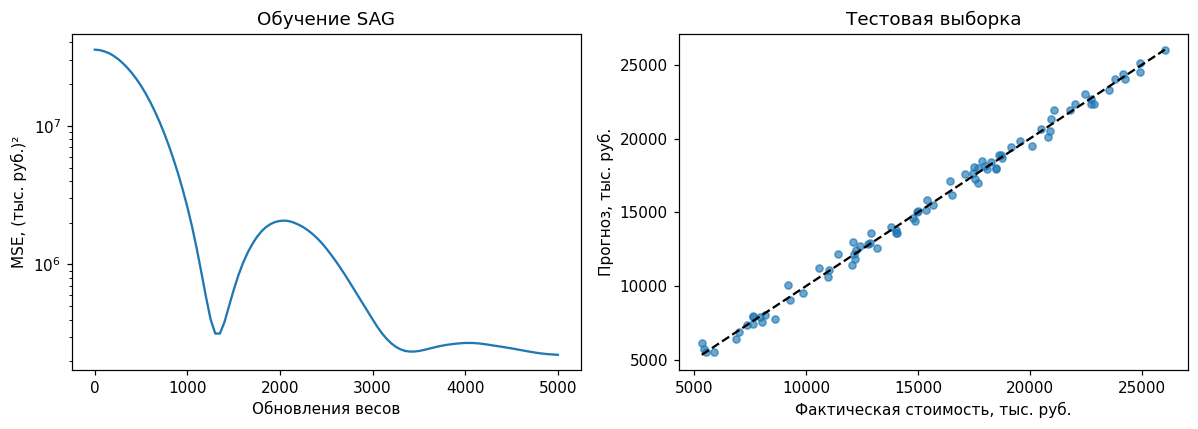

In [10]:
X_development = pd.concat([X_train, X_val])
y_development = pd.concat([y_train, y_val])
encoded_development, _ = encode(X_development, categories)
encoded_test, _ = encode(X_test, categories)
final_fit = prepare_fit(encoded_development[selected], y_development, encoded_test[selected], y_test)
final_model = fit_optimizer(final_fit["a"], final_fit["z"], best["Метод"],
                            best["Тип шага"], best["Параметр"], history=True)
if not final_model["valid"]:
    raise RuntimeError("Победитель разошёлся при обучении на train + val")
test_prediction = predict(final_fit, final_fit["check"], final_model["weights"])
test_metrics = metrics(y_test, test_prediction)
test_table = pd.DataFrame([{**test_metrics, "Метод": best["Метод"], "Шаг": best["Шаг"]}])
show_table(test_table.round(6))
save_table(test_table, "test_metrics")
save_table(pd.DataFrame({"ID_объекта": df.loc[test_idx, "ID_объекта"],
                         "Факт": y_test, "Прогноз": test_prediction}), "test_predictions")

xs, ys = final_fit["x_scaler"], final_fit["y_scaler"]
slopes = ys.scale_[0] * final_model["weights"][1:] / xs.scale_
intercept = ys.mean_[0] + ys.scale_[0] * final_model["weights"][0] - np.dot(xs.mean_, slopes)
save_table(pd.DataFrame({"Коэффициент": np.r_[intercept, slopes]},
                        index=["const"] + selected), "final_weights")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history = final_model["history"]
axes[0].plot(history[:, 0], history[:, 1] * ys.scale_[0] ** 2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Обновления весов")
axes[0].set_ylabel("MSE, (тыс. руб.)²")
axes[0].set_title(f"Обучение {best['Метод']}")
axes[1].scatter(y_test, test_prediction, alpha=0.65, s=22)
limits = [min(y_test.min(), test_prediction.min()), max(y_test.max(), test_prediction.max())]
axes[1].plot(limits, limits, color="black", linestyle="--")
axes[1].set_xlabel("Фактическая стоимость, тыс. руб.")
axes[1].set_ylabel("Прогноз, тыс. руб.")
axes[1].set_title("Тестовая выборка")
save_plot(fig, "test_and_convergence")

## 5. Вывод

In [11]:
conclusion = (
    f"Из {encoded_train.shape[1]} закодированных признаков оставлено {len(selected)}: "
    f"{', '.join(selected)}.\n"
    f"Модель на train {'значима' if final_stats['model'].iloc[0]['Значима'] else 'незначима'} "
    f"при α = {ALPHA}.\n"
    f"В проверенной сетке выбран {best['Метод']}, {best['Тип шага']}, {best['Шаг']}.\n"
    f"R² val = {best['R2_val']:.4f}, CV RMSE = {best['CV_RMSE']:.2f} тыс. руб.\n"
    f"На test: R² = {test_metrics['R2']:.4f}, RMSE = {test_metrics['RMSE']:.2f} тыс. руб.\n"
    "Вывод относится к проверенной сетке и выбранному разбиению."
)
print(conclusion)
(OUT / "conclusion.txt").write_text(conclusion + "\n", encoding="utf-8")
(OUT / "config.json").write_text(json.dumps({
    "seed": SEED, "alpha": ALPHA, "correlation_limit": CORR_LIMIT,
    "n_steps": N_STEPS, "n_folds": N_FOLDS, "grid": STEP_GRID.tolist(),
    "functional_step": "0.1 / (1 + lambda * k)", "features": selected,
    "selection": "min validation RMSE, then CV RMSE",
    "numpy": np.__version__, "pandas": pd.__version__,
}, ensure_ascii=False, indent=2), encoding="utf-8")

Из 16 закодированных признаков оставлено 4: Общая_площадь_м2, Этаж, Год_постройки, Расстояние_до_метро_мин.
Модель на train значима при α = 0.05.
В проверенной сетке выбран SAG, constant, η = 0.001.
R² val = 0.9955, CV RMSE = 475.41 тыс. руб.
На test: R² = 0.9945, RMSE = 412.82 тыс. руб.
Вывод относится к проверенной сетке и выбранному разбиению.
Out[11]: 555
